In [1]:
import betfair_data as bfd
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from itertools import groupby

# Import data

In [2]:
paths = glob.glob("data/2017-2021-BASIC-GB-IE-WIN.tar")
files = bfd.Files(paths)

markets = []
for f in files:
    for m in f:
        if m.bsp_market and \
            m.bsp_reconciled and \
            m.complete == True and \
            m.status == "CLOSED" and \
            m.market_type == "WIN":
            markets.append(m)

file: data/2017-2021-BASIC-GB-IE-WIN.tar/BASIC/2021/Aug/1/30746058/1.185863693.bz2 err: (JSON Parse Error) invalid type: integer `863693`, expected  at line 498 column 6
file: data/2017-2021-BASIC-GB-IE-WIN.tar/BASIC/2021/Apr/16/30429111/1.182015097.bz2 err: (JSON Parse Error) invalid type: integer `32635`, expected  at line 428 column 5
file: data/2017-2021-BASIC-GB-IE-WIN.tar/BASIC/2018/Dec/6/29038328/1.152160533.bz2 err: (JSON Parse Error) expected value at line 575 column 1
file: data/2017-2021-BASIC-GB-IE-WIN.tar/BASIC/2019/Feb/4/29110043/1.154433342.bz2 err: (JSON Parse Error) expected value at line 597 column 1
file: data/2017-2021-BASIC-GB-IE-WIN.tar/BASIC/2019/May/25/29299644/1.159156801.bz2 err: (JSON Parse Error) expected ident at line 427 column 2
file: data/2017-2021-BASIC-GB-IE-WIN.tar/BASIC/2020/Jul/28/29929023/1.171659519.bz2 err: (JSON Parse Error) expected value at line 403 column 1
file: data/2017-2021-BASIC-GB-IE-WIN.tar/BASIC/2020/Aug/15/29957385/1.172064782.bz2 er

Only the starting price is relevant for these strategies, so we can ignore all price movements.

In [3]:
# get the final time for each market
sorted_markets = sorted(markets, key=lambda m: (m.market_id, -m.version))
final_markets = [
    next(group)
    for _, group in groupby(sorted_markets, key=lambda m: m.market_id)
]

Place data into DataFrames for ease of use.

In [4]:
events = []
markets = []
runners = []
for m in final_markets:
    events.append({"event_id": m.event_id, "event_name": m.event_name, "event_date": m.open_date})
    markets.append({"event_id": m.event_id, "market_id": m.market_id, "market_name": m.market_name, "market_time": m.market_time})
    for race_no, r in enumerate(m.runners):
        runners.append({"market_id": m.market_id, "race_no": race_no+1, "runner_name": r.name, "start_price": r.sp.actual_sp, "status": r.status})
events = pd.DataFrame(events)
events.drop_duplicates(inplace=True)
events.set_index("event_id", inplace=True)
markets = pd.DataFrame(markets)
markets.set_index("market_id", inplace=True)
runners = pd.DataFrame(runners)
runners.set_index(["market_id", "race_no"], inplace=True)

/tmp/ipykernel_37430/114828918.py:5: DeprecationWarning: datetime.datetime.utcfromtimestamp() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.fromtimestamp(timestamp, datetime.UTC).
  events.append({"event_id": m.event_id, "event_name": m.event_name, "event_date": m.open_date})
/tmp/ipykernel_37430/114828918.py:6: DeprecationWarning: datetime.datetime.utcfromtimestamp() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.fromtimestamp(timestamp, datetime.UTC).
  markets.append({"event_id": m.event_id, "market_id": m.market_id, "market_name": m.market_name, "market_time": m.market_time})


# Utilities

In [5]:
# Get the nth market of each racing event
nth_markets = [runners.join(markets.sort_values("market_time").groupby("event_id").nth(i), on="market_id", how="inner") for i in range(8)]

In [8]:
def get_favourites(runners):
    return runners.sort_values("start_price").groupby("market_id").head(1)

## Graphing

In [9]:
def plot_trade_investment(trades, title="Investment Performance", axs=plt):
    #print(trades)
    if "stake" in trades:
        axs.plot(trades.market_time, trades.stake.cumsum(), label="Total Staked")
    axs.plot(trades.market_time, trades.value, label="Total Value")
    if axs == plt: axs.title(title)
    else: axs.set_title(title)
    axs.legend()

# General Statistics

In [10]:
nth_favourites = [get_favourites(x) for x in nth_markets]
all_favourites = get_favourites(runners).join(markets, on="market_id")

## Price of the favourite

### Per Race

In [12]:
fav_stats = []
for i, f in enumerate(nth_favourites, 1):
    fav_stats.append({
        "race_no": i,
        "win_rate": (f.status == "WINNER").mean(),
        "avg_price": f.start_price.mean(),
        "implied_odds": 1/f.start_price.mean()
    })
fav_stats = pd.DataFrame(fav_stats).set_index("race_no")

<Axes: xlabel='race_no'>

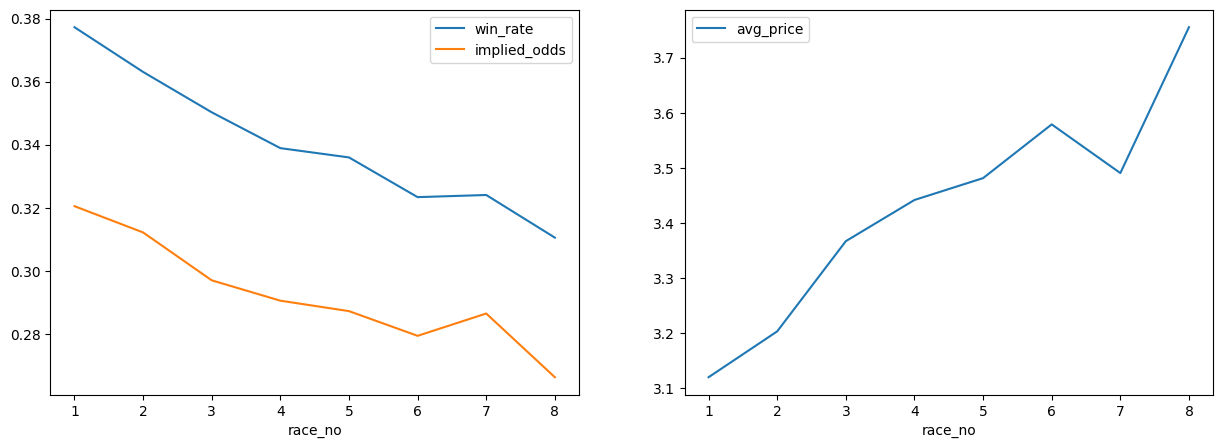

In [13]:
fig, axs = plt.subplots(1,2, figsize=(15,5))
fav_stats.plot(y=["win_rate", "implied_odds"], ax=axs[0])
fav_stats.plot(y="avg_price", ax=axs[1])

### Over Time

In [14]:
window_size = 1000

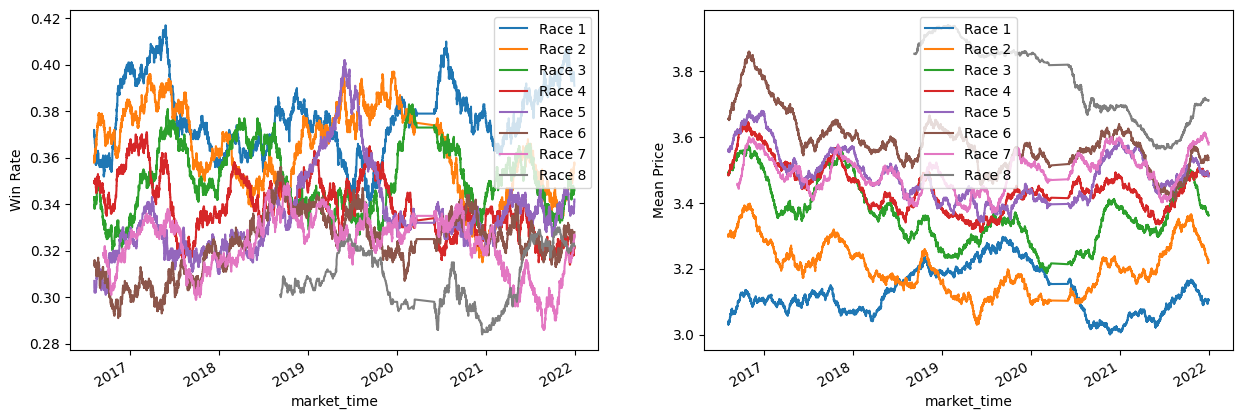

In [15]:
fig, axs = plt.subplots(1,2, figsize=(15,5))
for i, f in enumerate(nth_favourites, 1):
    fs = f.sort_values("market_time").set_index("market_time")
    (fs.status == "WINNER").rolling(window_size).mean().plot(label=f"Race {i}", ax=axs[0])
    fs.start_price.rolling(window_size).mean().plot(label=f"Race {i}", ax=axs[1])
axs[0].set_ylabel("Win Rate")
axs[0].legend()
axs[1].set_ylabel("Mean Price")
axs[1].legend()

In [16]:
window_size=10000

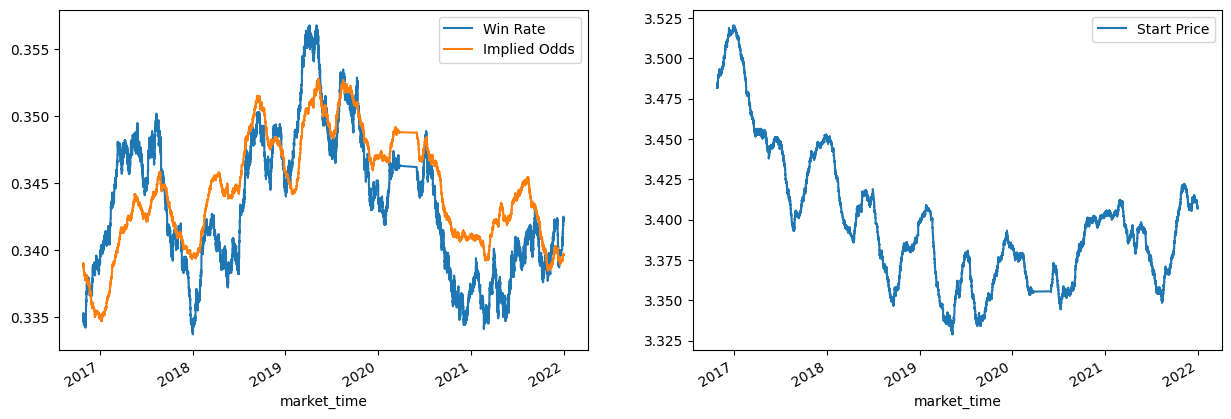

In [18]:
fig, axs = plt.subplots(1,2, figsize=(15,5))
fs = all_favourites.sort_values("market_time").set_index("market_time")
(fs.status == "WINNER").rolling(window_size).mean().plot(label="Win Rate", ax=axs[0])
(1/fs.start_price).rolling(window_size).mean().plot(label="Implied Odds", ax=axs[0])
fs.start_price.rolling(window_size).mean().plot(ax=axs[1], label="Start Price")
axs[0].legend()
axs[1].legend()

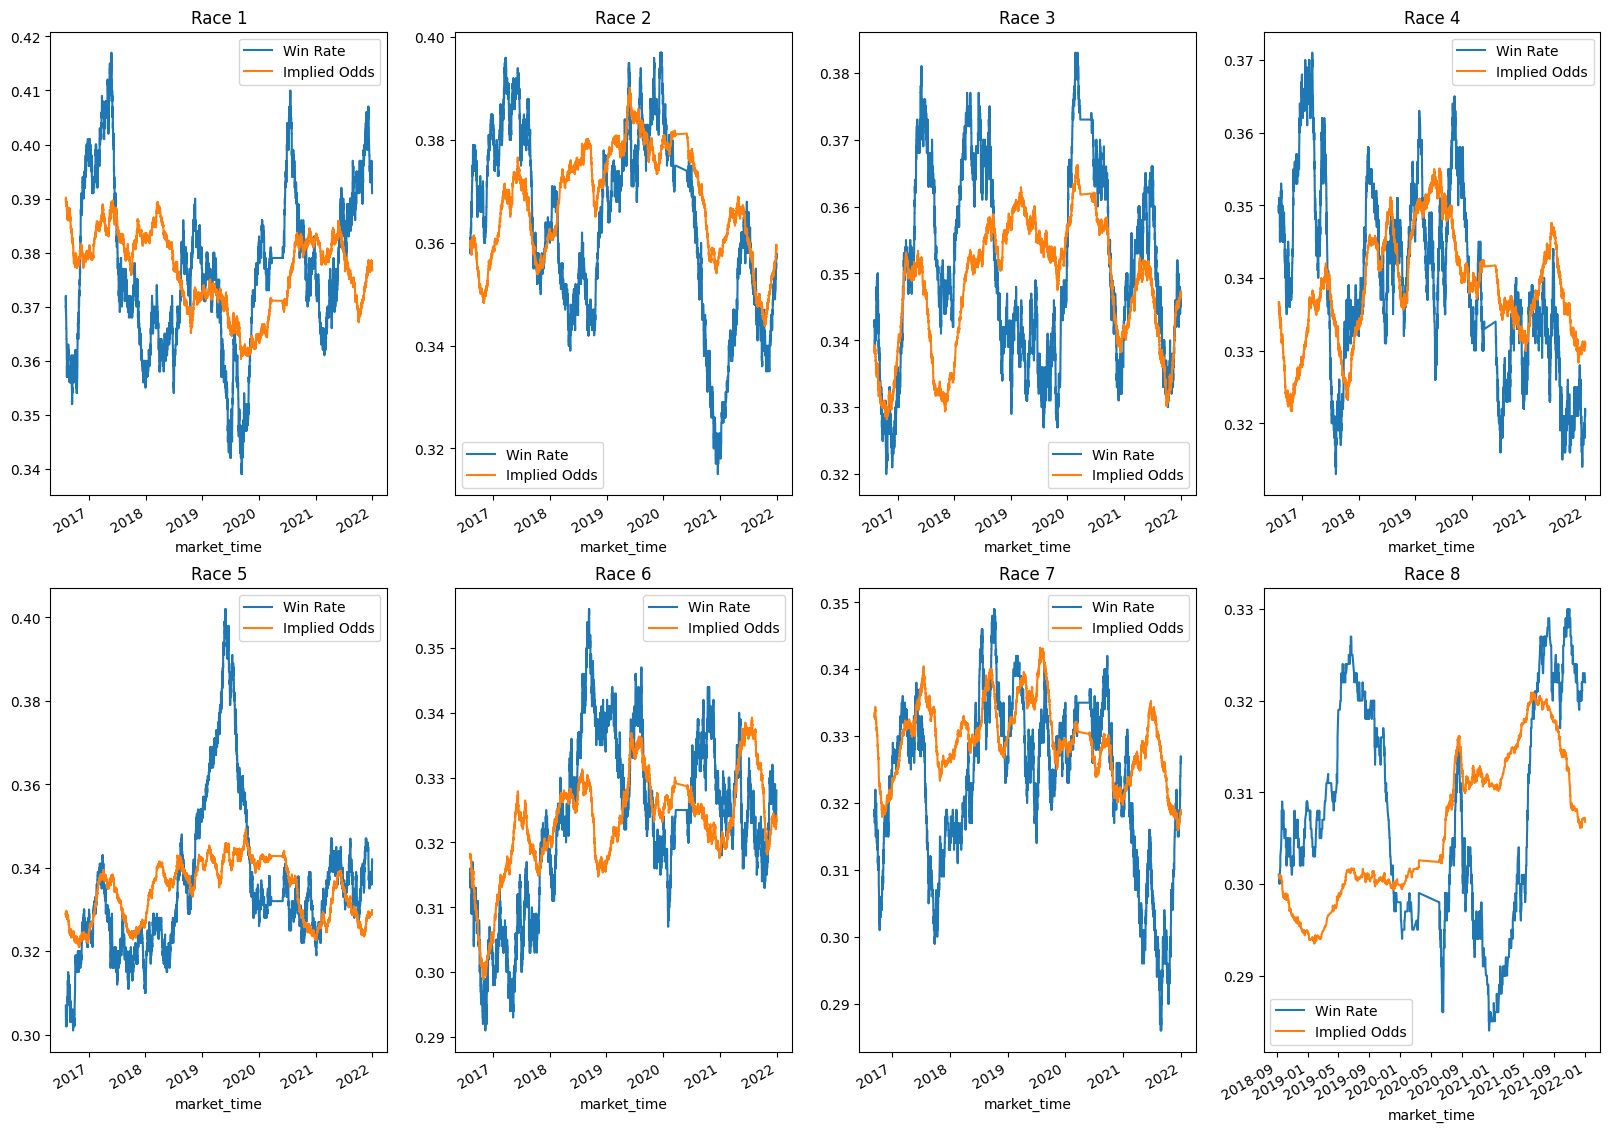

In [19]:
window_size = 1000
fig, axs = plt.subplots(2,4, figsize=(20,15))
axs = axs.flatten()
for i,f in enumerate(nth_favourites):
    f = f.sort_values("market_time").set_index("market_time")
    (f.status == "WINNER").rolling(window_size).mean().plot(label="Win Rate", ax=axs[i])
    (1/f.start_price).rolling(window_size).mean().plot(label="Implied Odds", ax=axs[i])
    axs[i].set_title(f"Race {i+1}")
    axs[i].legend()

## Accuracy of prices

Text(0.5, 1.0, 'Implied Odds Against Actual For All Favourites')

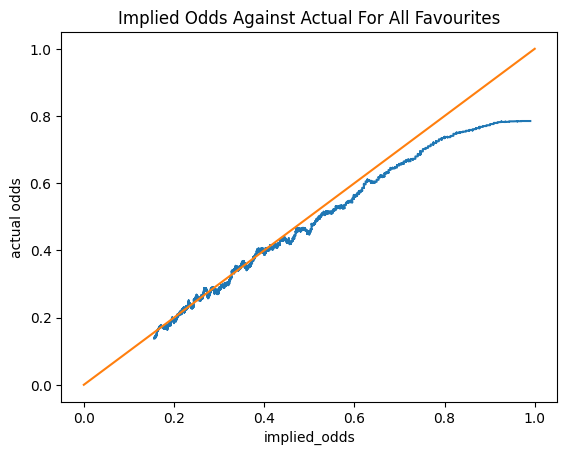

In [20]:
all_favourites[all_favourites.status.isin(["WINNER", "LOSER"])].assign(implied_odds=1/all_favourites.start_price).sort_values("implied_odds").set_index("implied_odds").status.map({"WINNER": 1, "LOSER": 0}).rolling(2000).mean().plot()
plt.ylabel("actual odds")
plt.plot([0,1],[0,1])
plt.title("Implied Odds Against Actual For All Favourites")

Text(0.5, 1.0, 'Implied Odds Against Actual For Favourites Per Race')

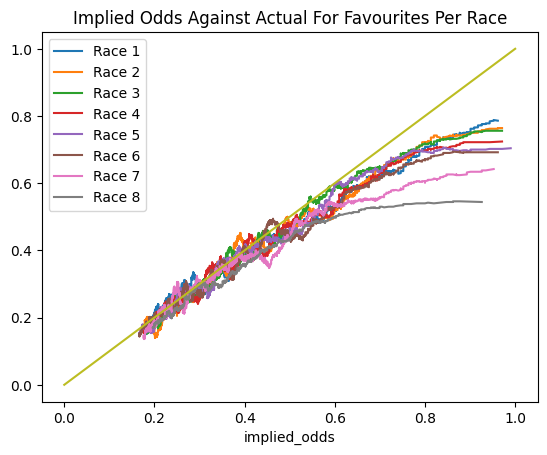

In [21]:
for i, f in enumerate(nth_favourites, 1):
    f[f.status.isin(["WINNER", "LOSER"])].assign(implied_odds=1/f.start_price).sort_values("implied_odds").set_index("implied_odds").status.map({"WINNER": 1, "LOSER": 0}).rolling(500).mean().plot(label=f"Race {i}")
plt.legend()
plt.plot([0,1],[0,1])
plt.title("Implied Odds Against Actual For Favourites Per Race")

# Define strategies

### Utilities

In [22]:
def action_trades(trades):
    t = trades.assign(profit=(trades.start_price * (trades.status=="WINNER") -1)*trades.stake)
    return t.assign(value=t.profit.cumsum())

In [23]:
def action_trades_percentage(trades):
    back = ((trades.start_price-1)*trades.percentage_stake) * (trades.status=="WINNER") + \
            -trades.percentage_stake * (trades.status == "LOSER")
    lay  = ((trades.percentage_liability/(trades.start_price-1)) * (trades.status=="LOSER")) + \
            -trades.percentage_liability * (trades.status == "WINNER")
    
    t = trades.assign(percentage_profit=back+lay)
    #t = trades.assign(stake = trades.iloc[1:] 
    t = t.assign(value=(t.percentage_profit+1).cumprod())
    return t

In [24]:
def create_timeline(trades): # Takes a DataFrame of trades and aligns them with market times to use for analysis
    return trades.merge(markets, on="market_id").sort_values("market_time")

## Betting on the favourite
The strategy simply bets one unit on the favourite for every race.

In [25]:
def bet_on_favourite(runners):
    favs = get_favourites(runners)
    trades = favs[["start_price", "status"]].assign(stake=1)
    return action_trades(create_timeline(trades))

## Hedging on the favourite
Similar to the previous strategy, but stakes are altered to adjust for implied risk. Stake is sized such that a succesful bet wins one unit.

In [26]:
def hedge_on_favourite(runners):
    favs = get_favourites(runners)
    trades = favs[["start_price", "status"]].assign(stake=1/favs["start_price"])
    return action_trades(create_timeline(trades))

## Learning Based Kelly-Criterion

This strategy involves looking at the likelihood of winning to inform the size of the bet.

$$f^* = p-\frac{q}{b}$$

In [27]:
def bet_kelly(runners, window_size=300, bet_size=0.005, back=True, lay=True):
    favs = get_favourites(runners).sort_values("market_time")
    p = (favs.status == "WINNER").rolling(window_size).mean()
    q = 1-p
    b = favs.start_price - 1
    #print(p[~p.isna()])
    trades = favs[["start_price", "status"]]
    trades = trades.assign(percentage_stake=p-q/b if back else 0)
    trades = trades.assign(percentage_liability=q-p/b if lay else 0)
    trades = trades[~trades.percentage_stake.isna() | ~trades.percentage_liability.isna()]
    trades.percentage_stake = trades.percentage_stake.clip(lower=0) * bet_size
    trades.percentage_liability = trades.percentage_liability.clip(lower=0) * bet_size
    #trades = trades[(trades.percentage_stake > 0) | (trades.percentage_liability > 0)]
    #trades.percentage_stake=0.4-trades.percentage_stake
    #trades = trades[trades.
    return create_timeline(action_trades_percentage(trades))

# Analysis

## Betting on the favourite

In [28]:
nth_trades = [bet_on_favourite(m) for m in nth_markets]
all_trades = bet_on_favourite(runners)

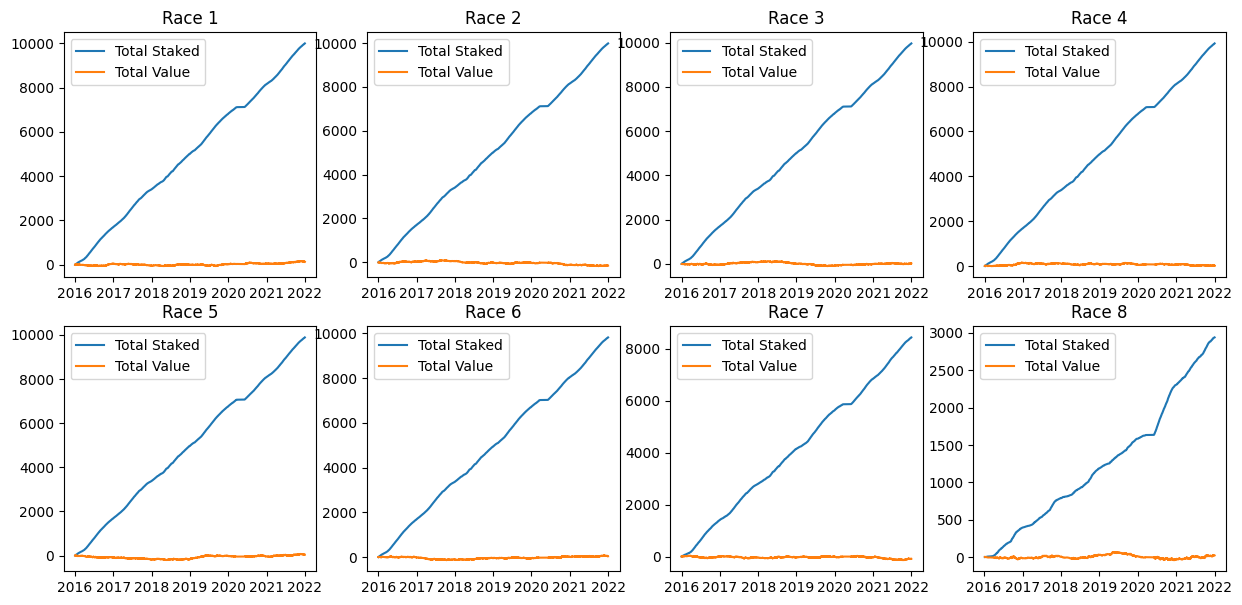

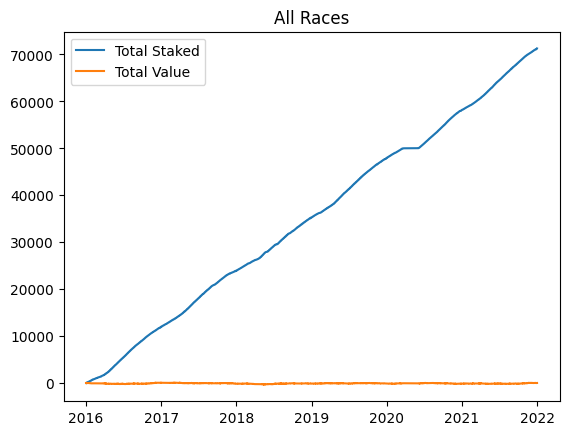

In [29]:
fig, axs = plt.subplots(2, 4, figsize=(15, 7))
axs = axs.flatten()
for i,t in enumerate(nth_trades):
    plot_trade_investment(t, f"Race {i+1}", axs[i])
plt.show()
plot_trade_investment(all_trades, "All Races")

## Hedging on the favourite

In [30]:
nth_trades = [hedge_on_favourite(m) for m in nth_markets]
all_trades = hedge_on_favourite(runners)

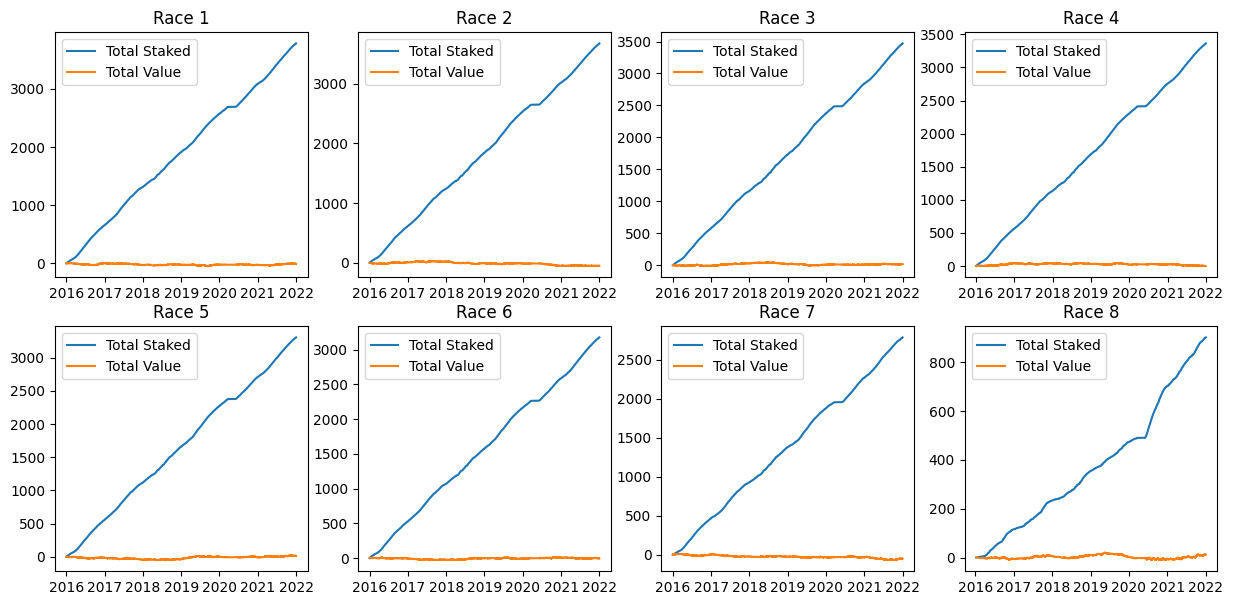

In [33]:
fig, axs = plt.subplots(2, 4, figsize=(15, 7))
axs = axs.flatten()
for i,t in enumerate(nth_trades):
    plot_trade_investment(t, f"Race {i+1}", axs[i]) 

## Learning Kelly

In [35]:
nth_trades = [bet_kelly(m, bet_size=0.006*8) for m in nth_favourites]
all_trades = bet_kelly(all_favourites, bet_size=0.006)

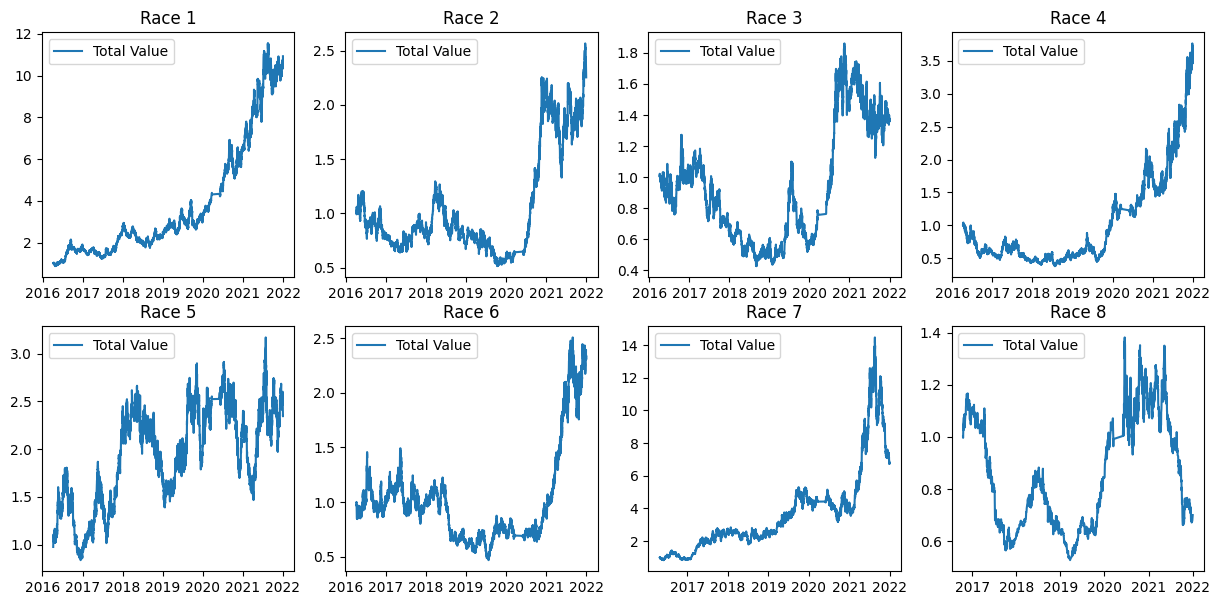

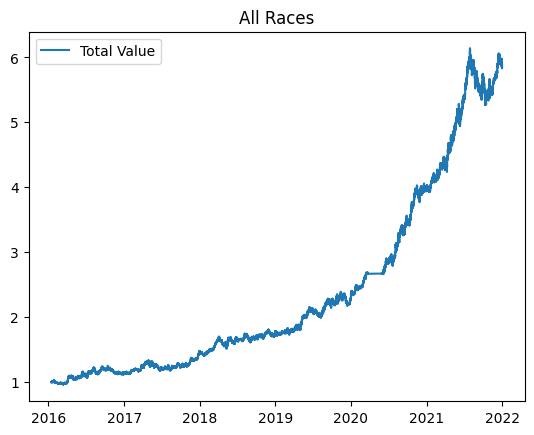

In [36]:
fig, axs = plt.subplots(2, 4, figsize=(15, 7))
axs = axs.flatten()
for i,t in enumerate(nth_trades):
    plot_trade_investment(t, f"Race {i+1}", axs[i])
plt.show()
plot_trade_investment(all_trades, "All Races")

In [48]:
all_trades

,start_price,status,percentage_stake,percentage_liability,percentage_profit,value,event_id,market_name,market_time
market_id,,,,,,,,,
1.122576498,4.37,LOSER,0.001176,0.003043,-0.000273,0.999727,27653664,2m6f Hcap Chs,2016-01-14 15:15:00
1.122576533,3.46,LOSER,0.000768,0.002793,0.000368,1.000094,27653665,2m3f Hcap Hrd,2016-01-14 15:25:00
1.122575608,1.90,WINNER,0.000000,0.001144,-0.001144,0.998950,27653606,1m3f Hcap,2016-01-14 15:40:00
1.122576503,1.72,WINNER,0.000000,0.000458,-0.000458,0.998493,27653664,3m Hunt Chs,2016-01-14 15:45:00
1.122576538,1.65,WINNER,0.000000,0.000111,-0.000111,0.998382,27653665,1m7f NHF,2016-01-14 15:55:00
...,...,...,...,...,...,...,...,...,...
1.192858942,1.82,WINNER,0.000000,0.000851,-0.000851,5.831301,31150498,2m2f Mares INHF,2021-12-31 15:00:00
1.192858890,3.36,LOSER,0.000732,0.002725,0.000423,5.833765,31150497,2m7f Hcap Hrd,2021-12-31 15:07:00
1.192858979,3.51,LOSER,0.000798,0.002812,0.000322,5.835645,31150507,2m NHF,2021-12-31 15:15:00


In [46]:
(all_trades.percentage_liability + all_trades.percentage_stake).max()

np.float64(0.005486740804106074)

In [53]:
all_trades.set_index("market_time").value.resample("YE").last().pct_change()

market_time
2016-12-31         NaN
2017-12-31    0.288086
2018-12-31    0.165966
2019-12-31    0.329278
2020-12-31    0.752782
2021-12-31    0.462961
Freq: YE-DEC, Name: value, dtype: float64